In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)

In [3]:
c_dict = {
    'Gast' : plt.cm.tab20c(12),
    'pSom' : plt.cm.tab20c(8),
    'Both' : 'darkgrey'}

In [4]:
# load manifold data from h5ad file
fn = os.path.join(pth_in, 'manifold.h5ad')
adata = sc.read_h5ad(fn); adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden', 'GSE162534', 'GSE229103', 'rRNAModifications', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'source_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [5]:
# select module genes — Gast | pSom (OR)
get_feat = lambda pth: pd.read_csv(pth).hsapiens
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = (pd.merge(gast, psom, 'outer')
     .hsapiens.drop_duplicates())
g = g.loc[g.isin(adata.var_names)]

In [6]:
# select cell-state convergence
msk = (adata.obs.celltype == 'Mixed')
adata_plt = adata[msk, g].copy()
adata_plt

AnnData object with n_obs × n_vars = 476 × 145
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden', 'GSE162534', 'GSE229103', 'rRNAModifications', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'source_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [7]:
# compute gene-module correlations -> sort
X = pd.DataFrame(adata_plt.X.toarray(),
                 index = adata_plt.obs_names,
                 columns = g)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.GSE162534.values[:, None]  # Gast
mod2 = adata_plt.obs.GSE229103.values[:, None]  # pSom
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

In [8]:
# assign module labels — Gast | pSom | Both
ix = R.index
msk_dict = {
    'Gast' : ix.isin(gast) & ~ix.isin(psom),
    'pSom' : ~ix.isin(gast) & ix.isin(psom),
    'Both' : ix.isin(gast) & ix.isin(psom)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

Gast 49
pSom 66
Both 24


In [9]:
# compute module mutual correlation
rval = np.corrcoef(
    *R.loc[~msk_dict['Both'], ['Gast', 'pSom']]
    .values.T)[0, 1].round(2)
print('r =', rval)

r = -0.49


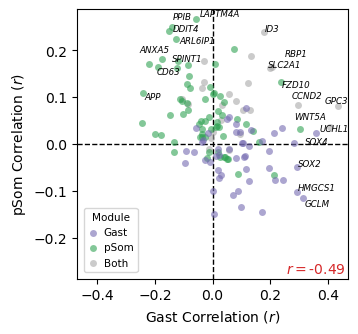

In [10]:
# plot gene-module correlations — scatter
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
# tune n, fontsize to avoid overlap
n, texts = 20, list()
for i in R.head(n).index:
    texts.append(ax.text(
        R.loc[i].Gast,
        R.loc[i].pSom,
        i, fontsize = 6.25,
        fontstyle = 'italic'))
adjust_text(texts = texts)

# plot legend
leg = ax.legend(title = 'Module',
                loc = 'lower left',
                title_fontsize = 7.5,
                handlelength = 1,
                handletextpad = .5,
                borderaxespad = .65,
                fontsize = 7.5,
                reverse = True)

# annotate module mutual correlation
ax.text(.99, .01, r'$r=$' + f'{rval}',
        transform = ax.transAxes,
        fontsize = 10, color = 'tab:red',
        ha = 'right', va = 'bottom')

ax.set_xlabel(r'Gast Correlation ($r$)')
ax.set_ylabel(r'pSom Correlation ($r$)')
fn = os.path.join(pth_out, 'modules.pdf')
plt.savefig(fn, bbox_inches = 'tight')